# Logistic regression

## Introduction

Logistic regression is one of the most widely used methods **for classification problems**. While linear regression uses a line (or a **hyperplane** with as many dimensions as independent variables) to predict the **continuous value** of the response variable, logistic regression fits a curve to **predict the probability** that the outcome variable belongs to a particular category or not.

It is important to emphasize that, although it is called "regression," **logistic regression is primarily used to solve classification problems, not regression problems**. The name comes from the fact that it models the relationship between features and the **log-odds** (or logit) of the outcome using a linear function - which is a form of regression. However, it transforms this linear combination through the **sigmoid function** to output probabilities between 0 and 1. The final prediction is made by applying a threshold (typically 0.5) to these probabilities to assign a class label.

## The Data

In this example, we will analyze the data of 100 students who applied for admission to a university. The selection process consists of two entrance exams and a personal interview. We have no data on how the students did in the interview, but we do have their exam scores and whether they were admitted. We will therefore consider two independent variables (the exam scores) and one dependent variable (admitted or not admitted).

The data are simulated. Each student's two scores, between 30 and 100, are added up together with what the interview contributed, which we never see (random, with a standard deviation of 10 points), and a total above 130 means admission. The interview is why similar scores don't always end in the same decision:

In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(seed=42)
exam1 = rng.uniform(30, 100, size=100).round(1)
exam2 = rng.uniform(30, 100, size=100).round(1)
interview = rng.normal(0, 10, size=100)  # not in the data: we never see it
admitted = np.where(exam1 + exam2 + interview > 130, "Yes", "No")
df = pd.DataFrame({"exam1": exam1, "exam2": exam2, "admitted": admitted})
df.head()

,exam1,exam2,admitted
0,84.2,93.6,Yes
1,60.7,79.0,Yes
2,90.1,48.6,Yes
3,78.8,97.8,Yes
4,36.6,84.5,No


## Logistic Regression with a Single Independent Variable

To further simplify, **we will initially analyze the possibility of being admitted based on only one independent variable (the score on the first entrance exam)**.

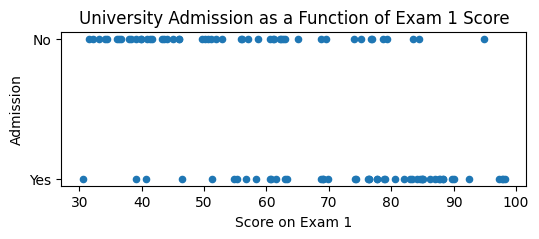

In [ ]:
df.plot(kind='scatter',  # Create a scatter plot
        x='exam1',       # with 'exam1' on the x-axis
        xlabel='Score on Exam 1',
        y='admitted',    # and 'admitted' on the y-axis
        ylabel='Admission',
        figsize=(6, 2),  # Reduce the height of the plot
        title='University Admission as a Function of Exam 1 Score');

By displaying all the data in a scatter plot, we can observe that admitted students generally have higher scores than non-admitted students, but the relationship is not linear, as the dependent variable can only take two values (admitted or not admitted) and not continuous values.

Still, we can give this data a probabilistic interpretation: the probability of being admitted increases with the exam score. We can look for a curve that gives that probability for any score, from 0 (never admitted) to 1 (always admitted).

The labels themselves are outcomes, not probabilities: each student was admitted or not, and the model estimates the probability of admission from many such outcomes. scikit-learn would accept the labels `'Yes'` and `'No'` as they are; we write them as 1 and 0 so that they can be drawn on the same axis as a probability:

In [ ]:
df['admitted'] = df['admitted'].map({'No': 0, 'Yes': 1})
df.head()

,exam1,exam2,admitted
0,84.2,93.6,1
1,60.7,79.0,1
2,90.1,48.6,1
3,78.8,97.8,1
4,36.6,84.5,0


In these cases, the sigmoid function allows us to obtain a curve that fits the data, being flat at the extremes (probability 0 or 1) and with a steeper slope in the center, leaving a transition zone between those where the probability of being admitted is high or very low.

$$ \sigma(x) = \frac{1}{1 + e^{-x}} $$

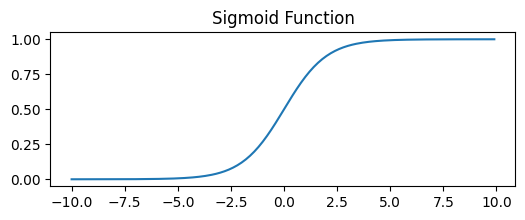

In [ ]:
from matplotlib import pyplot as plt


def sigmoid(x):
    return 1 / (1 + np.exp(-x))

x = np.arange(-10, 10, 0.1) # Example array for the sigmoid function

plt.figure(figsize=(6, 2))
plt.plot(x, sigmoid(x))
plt.title('Sigmoid Function')
plt.show()

This is the function that logistic regression uses to convert the linear combination of inputs into a probability.

**How it is fitted:** logistic regression looks for the weights that make the observed classes most probable (*maximum likelihood*), which is the same as minimising an error called the *log loss*. Unlike the squared error of linear regression, the log loss has no formula that gives the best weights directly, so they are found step by step, each step moving the weights a little in the direction that lowers the error: [Gradient descent](../../ml-fundamentals/gradient_descent.ipynb) explains how. scikit-learn's default solver, L-BFGS, is a refined version of that idea.

**Regularised by default:** scikit-learn's `LogisticRegression` adds a Ridge penalty to the log loss unless told otherwise ([Controlling complexity: regularisation](../../ml-fundamentals/regularization.ipynb)). Its strength is set with `C`, the *inverse* of the penalty: the default `C=1.0` penalises moderately, a larger `C` penalises less, and `C=np.inf` removes it (the older `penalty=None` is deprecated since scikit-learn 1.8). With features on very different scales, the penalty falls unevenly on their weights, so scaling them first matters here too.

We will use the ```LogisticRegression``` class from ```sklearn.linear_model``` to fit the model to our data:

In [ ]:
from sklearn.linear_model import LogisticRegression
# max_iter increases the maximum number of iterations for convergence
model = LogisticRegression(max_iter=1000).fit(df[['exam1']], df['admitted'])

With that fitted model, we can obtain predictions for a new value, using the ```predict``` method in the same way as with linear regression:

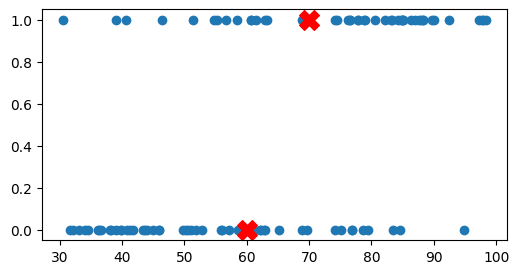

In [ ]:
plt.figure(figsize=(6, 3))
plt.scatter(df['exam1'], df['admitted'])
new_scores = pd.DataFrame({'exam1': [60, 70]}) # Create a new DataFrame with two scores
plt.scatter(new_scores, model.predict(new_scores), color='red', marker='X', s=200)
plt.show()

We can observe how the model predicts that a student with a score of 60 will not be admitted, but one with a score of 70 will be. The model is calculating where the cutoff point of the sigmoid curve is to determine whether the probability of being admitted is greater or less than 0.5, but we can have more information if instead of the prediction directly, what we obtain is the probability of being admitted, using the `predict_proba` method.

In [ ]:
print(model.classes_) # Classes detected by the model

proba_new_scores = model.predict_proba(new_scores)
print(proba_new_scores)

print(proba_new_scores[:,0]+proba_new_scores[:,1]) # The sum of the two columns is 1

[0 1]
[[0.58690369 0.41309631]
 [0.41264224 0.58735776]]
[1. 1.]


`predict_proba` returns an array with as many columns as possible values of the dependent variable (the categories). In this case the categories are 0 (not admitted) and 1 (admitted), as we can check in the `classes_` attribute of the model, so the array will have two columns, one with the probability of being admitted and another with the probability of not being admitted (which will be its complement, 1 - probability of being admitted).

Therefore, for this case, the information from the two columns is redundant, since if the probability of being admitted is 80%, the probability of not being admitted will be 20%, but with more than two categories every column matters: the first column is the probability of the first category of `classes_`, the second column of the second, and so on.

By creating an array of multiple possible values for X and generating their probabilities of being admitted, we can represent the sigmoid curve that fits the data:

In [ ]:
x_sigmoid = np.linspace(30, 100, 1000) # Array of 1000 values between 30 and 100 (x-axis limits we are using)
df_sigmoid = pd.DataFrame({'exam1': x_sigmoid}) # Create a new DataFrame with those hypothetical scores
y_sigmoid = model.predict_proba(df_sigmoid[['exam1']]) # Calculate the y values for those scores

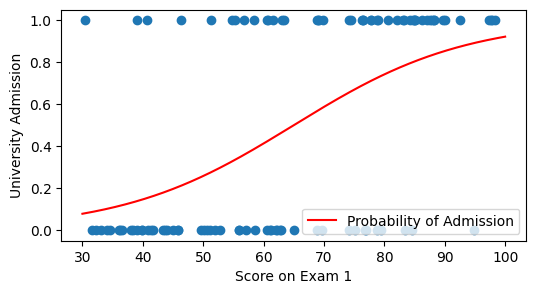

In [ ]:
plt.figure(figsize=(6, 3))

plt.plot(x_sigmoid, y_sigmoid[:, 1], 'r-', label='Probability of Admission')

plt.scatter(df['exam1'], df['admitted'])
plt.xlabel('Score on Exam 1')
plt.ylabel('University Admission')
plt.legend()
plt.show()

We can additionally display the probability of the other category (not being admitted) to see how the sum of both probabilities is always 1.

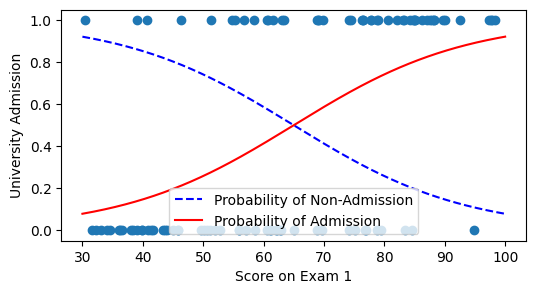

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(x_sigmoid, y_sigmoid[:, 0], 'b--', label='Probability of Non-Admission') # Probability of non-admission
plt.plot(x_sigmoid, y_sigmoid[:, 1], 'r-', label='Probability of Admission') # Probability of admission
plt.scatter(df['exam1'], df['admitted']) # Points from real data

plt.xlabel('Score on Exam 1')
plt.ylabel('University Admission')
plt.legend()
plt.show()

## Logistic Regression with Multiple Independent Variables

The normal approach will be to calculate this regression with both exam scores, since that's what we have. In this case, the sigmoid curve will be three-dimensional, as the probability of being admitted will depend on two independent variables.

We can do an initial exploration of the data by visualizing them with a scatter plot in which the color of the points indicates whether the student was admitted or not.

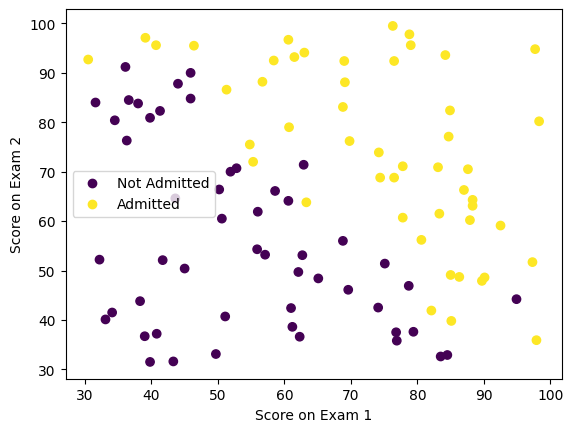

In [ ]:
scatter = plt.scatter(df['exam1'], df['exam2'], c=df['admitted']) 
plt.xlabel("Score on Exam 1")
plt.ylabel("Score on Exam 2")
plt.legend(scatter.legend_elements()[0], ['Not Admitted', 'Admitted'])
plt.show()

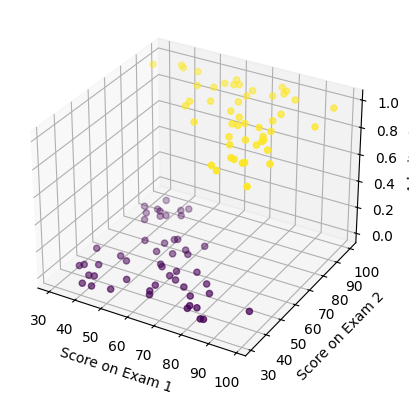

In [ ]:
fig = plt.figure()
ax = plt.axes(projection='3d')

x = df['exam1']
y = df['exam2']
z = df['admitted']

scatter = ax.scatter(x, y, z, c=z, cmap='viridis')

ax.set_xlabel('Score on Exam 1')
ax.set_ylabel('Score on Exam 2')
ax.set_zlabel('Admitted')

plt.show()

Admitted students tend to have higher scores on both exams, and the two groups are separated, roughly, by a straight line running from top left to bottom right. That is the shape logistic regression can draw: the probability is the sigmoid of a weighted sum of the two scores, so it is exactly 0.5 along a straight line.

If we want to use more than one independent variable, the process is the same, but instead of using a DataFrame with a single column, we will use a DataFrame with as many columns as independent variables we have.

In [ ]:
X = df.drop(columns="admitted")
y = df["admitted"]

model_multi = LogisticRegression(max_iter=1000).fit(X, y)
new_students = pd.DataFrame({"exam1": [55, 70, 85, 60], "exam2": [85, 70, 55, 60]})
new_students.assign(probability_of_admission=model_multi.predict_proba(new_students)[:, 1].round(3),
                    predicted=model_multi.predict(new_students))

,exam1,exam2,probability_of_admission,predicted
0,55,85,0.896,1
1,70,70,0.923,1
2,85,55,0.943,1
3,60,60,0.085,0


The first three students have 140 points each, split in different ways, and all three are admitted, with probabilities between 0.90 and 0.94: with these data the two exams weigh about the same, as in the simulation, where the rule simply added them. The fourth, with 120 points, has a probability of 0.08. The weights are learned from the admissions of the past, so the model can only repeat the criteria those admissions followed.

Instead of the 3D curve, we can simply represent in 2D the decision boundary (***decision boundary***), which is the place where the probability of being admitted is 50%.

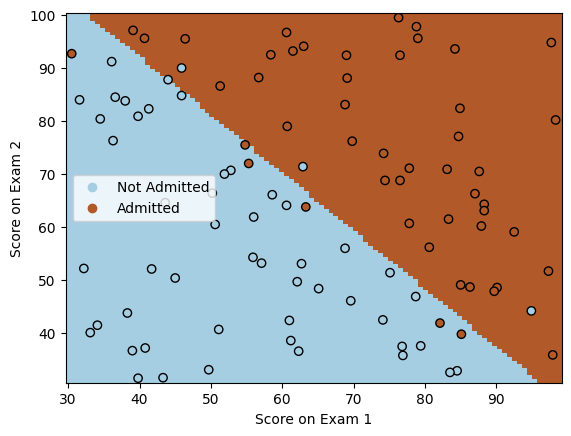

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay

_, ax = plt.subplots()
DecisionBoundaryDisplay.from_estimator( # Create a plot with the decision boundary
    model_multi,
    X,
    cmap='Paired',
    ax=ax,
    response_method="predict",
    plot_method="pcolormesh",
    shading="auto",
    xlabel="Score on Exam 1",
    ylabel="Score on Exam 2",
    eps=0.5,
)

scatter = plt.scatter(df['exam1'], df['exam2'], c=df['admitted'],
            edgecolors="k",
            cmap=plt.cm.Paired
            ) 

plt.xlabel("Score on Exam 1")
plt.ylabel("Score on Exam 2")
plt.legend(scatter.legend_elements()[0], ['Not Admitted', 'Admitted'])
plt.show()

## More than two classes

The iris dataset has three species of flower. Two measurements of the petals are enough to draw them in a plane:

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X_iris = iris.data[["petal length (cm)", "petal width (cm)"]]
y_iris = iris.target
iris_model = LogisticRegression(max_iter=1000).fit(X_iris, y_iris)
iris_model.classes_, iris.target_names

(array([0, 1, 2]), array(['setosa', 'versicolor', 'virginica'], dtype='<U10'))

With more than two classes, logistic regression computes one weighted sum per class, and turns the three sums into three probabilities that add up to 1 with the **softmax** function, the generalisation of the sigmoid: $P(\text{class } k) = \dfrac{e^{z_k}}{\sum_j e^{z_j}}$. For a flower with petals 5 cm long and 1.6 cm wide:

In [ ]:
flower = pd.DataFrame({"petal length (cm)": [5.0], "petal width (cm)": [1.6]})
pd.Series(iris_model.predict_proba(flower)[0], index=iris.target_names).round(3)

setosa        0.001
versicolor    0.474
virginica     0.525
dtype: float64

This flower lies on the border between two species: about 0.47 versicolor against 0.53 virginica, and almost no chance of setosa. The prediction is virginica, by a small margin that `predict` alone would hide.

The predicted class is the most probable one. Each pair of classes is separated by a straight line, so the plane is divided into three regions:

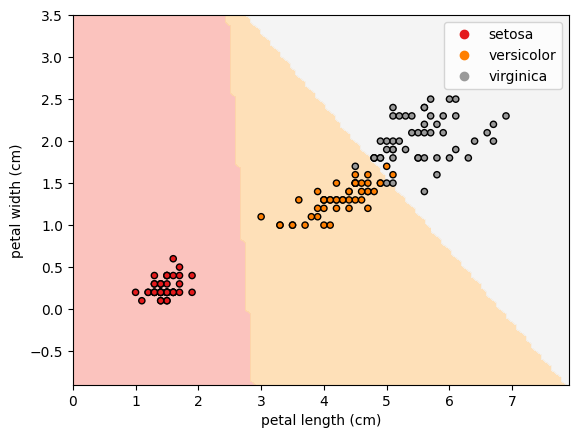

In [ ]:
_, ax = plt.subplots()
DecisionBoundaryDisplay.from_estimator(iris_model, X_iris, response_method="predict", multiclass_colors="Pastel1", ax=ax, alpha=0.8)
scatter = ax.scatter(X_iris.iloc[:, 0], X_iris.iloc[:, 1], c=y_iris, cmap="Set1", edgecolors="k", s=20)
ax.legend(scatter.legend_elements()[0], iris.target_names)
plt.show()

Some classifiers can only separate two classes. They are extended to more by training one classifier per class against all the others (*one-vs-rest*), or one per pair of classes (*one-vs-one*): [A classifier in depth (MNIST)](../../evaluation/deep-dives/mnist_classifier_in_depth.ipynb) compares the two.

## Sources and Supplementary Material

- https://aprendeia.com/algoritmo-regresion-logistica-machine-learning-teoria/ (in Spanish)
- https://cienciadedatos.net/documentos/py17-regresion-logistica-python.html (in Spanish)
- https://nbviewer.org/github/jdwittenauer/ipython-notebooks/blob/master/notebooks/ml/ML-Exercise2.ipynb
- https://realpython.com/logistic-regression-python/
- https://cesguiro.es/doku.php?id=clase:ia:saa:2eval:clasificacion_modelos_1 (in Spanish)